In [15]:
import joblib
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import precision_score, roc_auc_score, f1_score
from sklearn.metrics import accuracy_score, recall_score
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay



In [16]:
X_train_tfidf, X_test_tfidf, y_train, y_test, tfidf = joblib.load(
    "data/preprocessed_data.joblib"
)

In [17]:
model = MultinomialNB()

model.fit(X_train_tfidf, y_train)
y_pred = model.predict(X_test_tfidf)

print("Predicted:", y_pred[:5].tolist())
print("Actual:   ", y_test.iloc[:5].tolist())

Predicted: [1, 0, 0, 0, 0]
Actual:    [1, 0, 0, 0, 0]


In [18]:
print(f"Accuracy: {accuracy_score(y_test, y_pred):.1%}")
print(f"Spam Recall: {recall_score(y_test, y_pred):.1%}")
print(f"Spam Precision: {precision_score(y_test, y_pred):.1%}")
print(f"Spam F1: {f1_score(y_test, y_pred):.1%}")

Accuracy: 90.5%
Spam Recall: 68.8%
Spam Precision: 100.0%
Spam F1: 81.5%


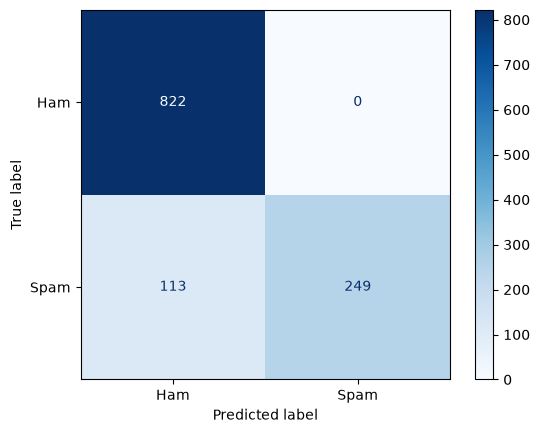

In [19]:

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1],
    display_labels=["Ham", "Spam"],
    cmap="Blues"
)

plt.show()

ROC-AUC: 0.9965


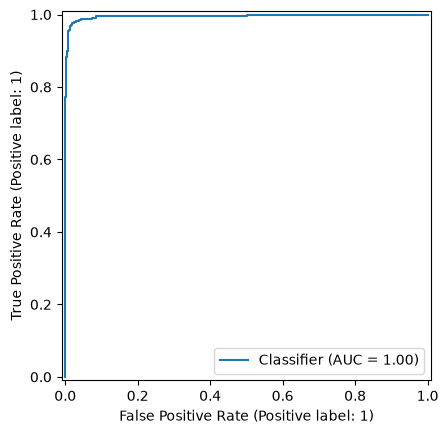

In [20]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, RocCurveDisplay

spam_scores = model.predict_proba(X_test_tfidf)[:, 1]

auc = roc_auc_score(y_test, spam_scores)
print(f"ROC-AUC: {auc:.4f}")

RocCurveDisplay.from_predictions(y_test, spam_scores)
plt.show()